## Jezikovni model na osnovi transformerja
Zgradili bomo majhen GPT-2 model in ga naučili govoriti slovensko tako kot Cankar.

In [1]:
import torch
import numpy as np
import pickle

from transformers import AutoTokenizer

torch.manual_seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"

/Users/jan/repositories/PSUF/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Tokenizer

In [2]:
# enostaven tokenizer - po znakih
with open("data/simple_tokenizer.pkl", "rb") as f:
    tokenizer = pickle.load(f)

train_ids = np.load("data/simple_tok_train.npy")
val_ids = np.load("data/simple_tok_val.npy")

# gams tokenizer - po delih besed
# tokenizer = AutoTokenizer.from_pretrained("data/tokenizer_gams1b")
# train_ids = np.load("data/gams1b_tok_train.npy")
# val_ids = np.load("data/gams1b_tok_val.npy")

vocab_size = tokenizer.vocab_size

In [3]:
# celotno besedilo je zaporedje celih števil
train_data = torch.tensor(train_ids, dtype=torch.long)
val_data = torch.tensor(val_ids, dtype=torch.long)

## Dolžina konteksta

In [4]:
block_size = 8 # context length, največja dolžina napovedi
train_data[:block_size + 1] # napovedovali bomo kaj pride po nizu celih števil

tensor([45, 46,  1, 67, 60, 71, 60, 58,  0])

In [5]:
x = train_data[:block_size]
y = train_data[1:block_size + 1]

for i in range(block_size):
    context = x[:i + 1]
    target = y[i]
    # transformer bo videl do block_size, po tem bomo začeli rezati
    print(f"{i}: pri {context.tolist()} je tarča {target}.")

0: pri [45] je tarča 46.
1: pri [45, 46] je tarča 1.
2: pri [45, 46, 1] je tarča 67.
3: pri [45, 46, 1, 67] je tarča 60.
4: pri [45, 46, 1, 67, 60] je tarča 71.
5: pri [45, 46, 1, 67, 60, 71] je tarča 60.
6: pri [45, 46, 1, 67, 60, 71, 60] je tarča 58.
7: pri [45, 46, 1, 67, 60, 71, 60, 58] je tarča 0.


## Velikost paketa

In [6]:
batch_size = 4 # koliko neodvisnih nizov bomo procesirali na enkrat v forward/backward

def get_batch(split: str) -> tuple[torch.Tensor, torch.Tensor]:
    if split == "train":
        data = train_data
    elif split == "val":
        data = val_data
    else:
        raise ValueError(f"Split must be `train` or `val` and not {split}.")

    idx = torch.randint(len(data) - block_size, (batch_size, )) # random offsets

    # vrstice v tenzorju (vrstice so neodvisne)
    x = torch.stack([data[i:i + block_size] for i in idx]) # rabimo za učenje
    y = torch.stack([data[i + 1:i + block_size + 1] for i in idx]) # rabimo za funkcijo izgube

    return x.to(device), y.to(device)

In [7]:
x_b, y_b = get_batch("train")

print(f"Vhodni podatki ({x_b.shape}):\n{x_b}")
print(f"Tarče ({y_b.shape}):\n{y_b}")

Vhodni podatki (torch.Size([4, 8])):
tensor([[52, 60, 65, 60, 67, 60,  1, 65],
        [71, 58, 50, 63, 60, 58,  1, 47],
        [63, 54, 64, 65, 55, 46, 59, 60],
        [73, 54, 65, 59, 60,  1, 63, 46]])
Tarče (torch.Size([4, 8])):
tensor([[60, 65, 60, 67, 60,  1, 65, 66],
        [58, 50, 63, 60, 58,  1, 47, 60],
        [54, 64, 65, 55, 46, 59, 60, 58],
        [54, 65, 59, 60,  1, 63, 46, 71]])


In [8]:
for b in range(batch_size):
    for i in range(block_size):
        context = x_b[b, :i + 1]
        target = y_b[b, i]
        print(f"Ko je vhodna vrednost {context.tolist()} je tarča {target}.")

Ko je vhodna vrednost [52] je tarča 60.
Ko je vhodna vrednost [52, 60] je tarča 65.
Ko je vhodna vrednost [52, 60, 65] je tarča 60.
Ko je vhodna vrednost [52, 60, 65, 60] je tarča 67.
Ko je vhodna vrednost [52, 60, 65, 60, 67] je tarča 60.
Ko je vhodna vrednost [52, 60, 65, 60, 67, 60] je tarča 1.
Ko je vhodna vrednost [52, 60, 65, 60, 67, 60, 1] je tarča 65.
Ko je vhodna vrednost [52, 60, 65, 60, 67, 60, 1, 65] je tarča 66.
Ko je vhodna vrednost [71] je tarča 58.
Ko je vhodna vrednost [71, 58] je tarča 50.
Ko je vhodna vrednost [71, 58, 50] je tarča 63.
Ko je vhodna vrednost [71, 58, 50, 63] je tarča 60.
Ko je vhodna vrednost [71, 58, 50, 63, 60] je tarča 58.
Ko je vhodna vrednost [71, 58, 50, 63, 60, 58] je tarča 1.
Ko je vhodna vrednost [71, 58, 50, 63, 60, 58, 1] je tarča 47.
Ko je vhodna vrednost [71, 58, 50, 63, 60, 58, 1, 47] je tarča 60.
Ko je vhodna vrednost [63] je tarča 54.
Ko je vhodna vrednost [63, 54] je tarča 64.
Ko je vhodna vrednost [63, 54, 64] je tarča 65.
Ko je vhod

## Pogovarjanje med tokeni
Radi bi, da bi token na mestu $n$ videl vse tokene ki so prišli pred njim v $x[:n-1]$ v nekem kontekstnem oknu (a *ne* tistih v prihodnosti). Uporabili bomo matrično množenje s spodnje diagonalno matriko in funkcijo softmax:
$$
\text{softmax}(z)_i=\frac{e^{z_i}}{\sum_{j=1}^K e^{z_j}} \>.
$$

In [9]:
import torch.nn as nn
from torch.nn import functional as F

In [10]:
B, T, C = 4, 8, 2
x = torch.randn(B, T, C) # podatki, tokeni

tril = torch.tril(torch.ones(T, T)) # spodnje trikotna matrika

# uteži nevronske mreže, to se bomo naučili in bodo odvisne od podatkov
w = torch.zeros((T, T)) # moč interakcije, koliko vsakega tokena iz preteklosti hočemo uporabiti in povprečiti
w = w.masked_fill(tril == 0, float("-inf")) # tokeni v prihodnosti ne morejo komunicirati
w = F.softmax(w, dim=-1)

In [11]:
w

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3333, 0.3333, 0.3333, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2500, 0.2500, 0.2500, 0.2500, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2000, 0.2000, 0.2000, 0.2000, 0.2000, 0.0000, 0.0000, 0.0000],
        [0.1667, 0.1667, 0.1667, 0.1667, 0.1667, 0.1667, 0.0000, 0.0000],
        [0.1429, 0.1429, 0.1429, 0.1429, 0.1429, 0.1429, 0.1429, 0.0000],
        [0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250]])

In [12]:
w @ x # matrično množenje, weighted aggregation of past elements

tensor([[[ 0.6784, -1.2345],
         [ 0.3177, -1.4196],
         [ 0.8077, -1.1058],
         [ 0.5451, -1.0629],
         [ 0.2905, -0.9622],
         [ 0.1139, -0.6747],
         [-0.1263, -0.6126],
         [ 0.1799, -0.6564]],

        [[-0.7581,  1.0783],
         [ 0.0213,  1.3795],
         [ 0.1328,  0.6908],
         [-0.0237,  0.5785],
         [-0.0653,  0.4711],
         [-0.0963,  0.5359],
         [-0.1268,  0.4028],
         [-0.0105,  0.2748]],

        [[ 0.3189, -0.4245],
         [ 0.3123, -0.5996],
         [ 0.2198, -0.2927],
         [ 0.5583, -0.4309],
         [ 0.1918,  0.0799],
         [-0.0459, -0.0148],
         [-0.2420,  0.1154],
         [-0.2055,  0.3843]],

        [[-0.4880,  1.1914],
         [-0.6510,  0.2277],
         [-0.7130, -0.1557],
         [-0.0820, -0.0766],
         [-0.0851,  0.3076],
         [-0.2684,  0.4869],
         [-0.4018,  0.5185],
         [-0.4861,  0.5206]]])

## Samopozornost (self-attention)
Vsak token na vsakem položajo bo imel dva vektorja vsakega s svojo vlogo:
- $q$ poizvedba (*query*), kaj gledam?
- $k$ ključ (*key*), kaj vsebujem?

In [13]:
from einops import einsum

In [14]:
head_size = 16
key = nn.Linear(C, head_size, bias=False)
query = nn.Linear(C, head_size, bias=False)

In [15]:
k = key(x) # (B, T, head_size)
q = query(x) # (B, T, head_size)

In [16]:
# w = q @ k.transpose(-2, -1)
# visoka vrednost pomeni: ta ključ se ujema s to poizvedbo (s tem vprašanjem)
w = einsum(q, k, "b t1 h, b t2 h -> b t1 t2") # (B, T, head_size) @ (B, head_size, T) = (B, T, T)

#### einops notacija
Pravila za branje izraza "b t1 h, b t2 h -> b t1 t2":

1. **Isto ime v več vhodih pomeni isti indeks**. Vrednosti vzdolž te osi se med vhodi poravnajo, zato morajo biti dolžine enake. Tu se b in h pojavita v q in v k.
2. **Imena, ki so v izhodu, se ohranijo**. b, t1 in t2 ostanejo, zato ima rezultat obliko (B, T, T), v vrstnem redu, ki je zapisan za ->.
3. **Imena, ki jih v izhodu ni, se seštejejo**. h je v vhodih, v izhodu pa ne, zato se produkti vzdolž h seštejejo.

Izraz torej pomeni: za vsak b, t1 in t2 zmnoži q in k element za elementom vzdolž h in vse seštej. To je natanko skalarni produkt poizvedbe t1 s ključem t2, za vsak element tokena posebej.

Uporabne so še naslednje funkcije:
```python
from einops import rearrange

rearrange(x, "h w -> w h")
rearrange(x, "h w -> (h w)")
rearrange(y, "(h w) -> h w", h=H)
rearrange(x, "h w -> (w h)")
```

```python
from einops import reduce

reduce(x, "b t c -> b c", "mean") # sum, max, ...
```

```python
from einops import repeat

repeat(pos_emb, "t c -> b t c", b=B)
```

In [17]:
w = w * head_size**-0.5 # zaradi variance

### Vzročna samopozornost

In [18]:
w = w.masked_fill(tril == 0, float("-inf"))
w = F.softmax(w, dim=-1) # porazdelitev: kdo koga posluša

In [19]:
value = nn.Linear(C, head_size, bias=False) # definiramo še vrednosti na enak način
v = value(x) # pove katero informacijo naj vzamemo (w pove koliko, v pove kaj)

In [20]:
out = w @ v # utežena vsota vrednosti
out.shape # (B, T, head_dim)

torch.Size([4, 8, 16])

In [21]:
import matplotlib.pyplot as plt

def plot_weights(w: torch.Tensor, tokens: list[str] | None = None):
    """w: (T, T), vrstice = queries, stolpci = keys."""
    T = w.shape[0]
    tokens = tokens or [str(i) for i in range(T)]

    fig, ax = plt.subplots(figsize=(5, 4.5))
    cmap = plt.get_cmap("Blues").copy()
    cmap.set_bad("#eeeeee")
    im = ax.imshow(w.masked_fill(w == 0, float("nan")), cmap=cmap)

    ax.set_xticks(range(T), tokens, rotation=45, ha="right")
    ax.set_yticks(range(T), tokens)
    ax.set_xlabel("ključ (key)")
    ax.set_ylabel("poizvedba (query)")
    ax.set_title("Uteži pozornosti")

    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="utež")
    fig.tight_layout()
    plt.show()

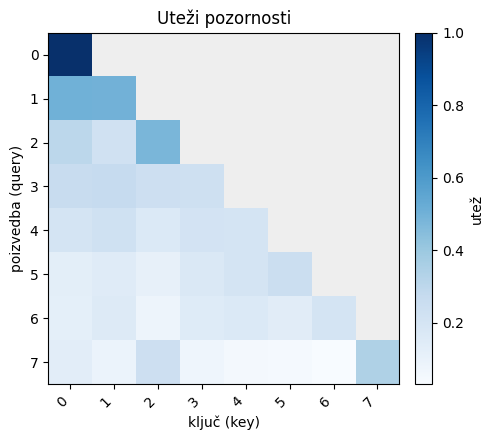

In [22]:
plot_weights(w[0, :, :].detach())

In [23]:
w[0, :, :].sum(dim=-1) # normalizirano zaradi softmax

tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000],
       grad_fn=<SumBackward1>)

### Samopozornost kot graf

Tokene v nekem kontekstnem oknu si lahko predstavljamo kot vozlišča grafa. Matrika pozornosti $w$ je njegova matrika sosednosti (adjacency matrix). Elementi $w_{ij}$ so uteži usmerjene povezave od tokene $i$ k tokenu $j$ in pove koliko token $i$ "posluša" token $j$.

<img src="images/self_attention_graph.png" width="900"/>

Vsako vozlišče $j$ ima svoje sporočilo, to je vrednost $v_j$. Vsako vozlišče $i$ izbere sporočilo svojih sosedov uteženo z utežmi povezav:
$$
\text{out}_i = \sum_j w_{ij} v_j \>.
$$
Poizvedbe in ključi torej določijo, kdo je s kom povezan (in kako močno), vrednosti pa, kaj potuje po povezavah. To je isto načelo kot pri grafovskih nevronskih mrežah (graph neural networks, GNN), le da graf ni podan vnaprej: model ga z naučenimi preslikavami sproti izračuna iz vhoda.

## Glava modela

In [24]:
class Head(nn.Module):
    tril: torch.Tensor
    
    def __init__(self, head_size: int, n_embed: int, block_size: int) -> None:
        super().__init__()
        self.key = nn.Linear(n_embed, head_size, bias=False)
        self.query = nn.Linear(n_embed, head_size, bias=False)
        self.value = nn.Linear(n_embed, head_size, bias=False)

        self.register_buffer("tril", troch.tril(torch.ones(block_size, block_size))) # ni parameter modela, to je buffer

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Scaled dot-product attention."""
        B, T, C = x.shape

        q = self.query(x) # (B, T, C)
        k = self.key(x) # (B, T, C)

        w = einsum(q, k, "b t1 h, b t2 h -> b t1 t2") * C**-0.5 # (B, T, T)
        w = w.masked_fill(self.tril[:T, :T] == 0, float("-inf")) # (B, T, T)
        w = F.softmax(w, dim=-1) # (B, T, T)

        v = self.value(x)
        out = einsum(w, x, "b t1 t2, b t2 c -> b t1 c") # (B, T, C)

        return out

## Večglava pozornost (multi-head self-attention)

Namesto da bi izvedli eno samo funkcijo pozornosti s ključi, vrednostmi in poizvedbami dimenzije je koristneje poizvedbe, ključe in vrednosti $h$-krat linearno preslikati z različnimi naučenimi linearnimi preslikavami. Na vsaki od teh preslikanih različic poizvedb, ključev in vrednosti nato vzporedno izvedemo funkcijo pozornosti. Te izhode združimo in ponovno linearno preslikamo, s čimer dobimo končne vrednosti.

Večglava pozornost modelu omogoča, da hkrati upošteva informacije iz različnih podprostorov na različnih položajih. Pri eni sami glavi pozornosti to preprečuje povprečenje.

<img src="images/multihead_attention.png" width="1100"/>
$$
\begin{align}
  q_h &= x\, W_Q^{(h)}, \qquad
  k_h  = x\, W_K^{(h)}, \qquad
  v_h  = x\, W_V^{(h)},
  && h = 1, \dots, n_h, \\[4pt]
  w_h &= \operatorname{softmax}\!\left( \frac{q_h k_h^\top}{\sqrt{h_s}} + M \right),
  \qquad M_{ij} =
     \begin{cases}
       0       & j \le i, \\
       -\infty & j > i,
     \end{cases} \\[4pt]
  o_h &= w_h\, v_h, \\[4pt]
  y   &= \bigl[\, o_1 \;\; o_2 \;\; \cdots \;\; o_{n_h} \,\bigr]\, W_O .
\end{align}
$$

In [25]:
class BigramLanguageModel(nn.Module):
    def __init__(self, vocab_size: int, n_embed: int, block_size: int) -> None:
        super().__init__()
        # vložitvene (embedding) matrike
        self.token_embedding_table = nn.Embedding(vocab_size, n_embed) # vložitev za tokene (identitea tokena), (T, C)
        self.position_embedding_table = nn.Embedding(block_size, n_embed) # vložitev za pozicije tokenov

        # preslikava iz C (n_embed) v vocab_size
        self.to_logits_head = nn.Linear(n_embed, vocab_size) # plast, ki nam bo dala logite

    def forward(self, idx: torch.Tensor, targets: torch.Tensor | None = None) -> tuple[torch.Tensor, torch.Tensor | None]:
        B, T = idx.shape

        # vsak int bo dobil iz embedding tabele vrstico, ki ustreza njegovemu indeksu
        token_embedding = self.token_embedding_table(idx) # (B, T, C), C = n_embed
        position_embedding = self.position_embedding_table(torch.arange(T, device=idx.device)) # (T, C)

        x = token_embedding + position_embedding # (B, T, C)
        logits = self.to_logits_head(x) # (B, T, vocab_size)

        if targets is None:
            return logits, None

        B, T, C = logits.shape
        logits = logits.view(B * T, C)
        targets = targets.view(B * T)
        loss = F.cross_entropy(logits, targets)

        return logits, loss

    def generate(self, idx: torch.Tensor, max_new_tokens: int) -> torch.Tensor:
        for _ in range(max_new_tokens):
            logits, loss = self(idx) # (B, T, C)
            logits = logits[:, -1, :] # zadnji token, (B, C)
            probs = F.softmax(logits, dim=-1) # verjetnosti, (B, C)
            idx_next = torch.multinomial(probs, num_samples=1) # vzorčimo porazdelitev, (B, 1)
            idx = torch.cat((idx, idx_next), dim=1) # pripnemo ID k trenutnemu nizu

        return idx

## Model

In [26]:
import torch.nn as nn
from torch.nn import functional as F

In [27]:
class BigramLanguageModel(nn.Module):
    def __init__(self, vocab_size: int) -> None:
        super().__init__()
        self.embedding_table = nn.Embedding(vocab_size, vocab_size) # matrika (vocab_size, vocab_size)

    def forward(self, idx: torch.Tensor, targets: torch.Tensor | None = None) -> tuple[torch.Tensor, torch.Tensor | None]:
        # vsak int bo dobil iz embedding tabele vrstico, ki ustreza njegovemu indeksu
        logits = self.embedding_table(idx) # (B, context, vocab_size)

        if targets is None:
            return logits, None

        B, C, vocab_size = logits.shape
        logits = logits.view(B * C, vocab_size)
        targets = targets.view(B * C)
        loss = F.cross_entropy(logits, targets)

        return logits, loss

    def generate(self, idx: torch.Tensor, max_new_tokens: int) -> torch.Tensor:
        for _ in range(max_new_tokens):
            logits, loss = self(idx) # (batch, context, vocab_size)
            logits = logits[:, -1, :] # zadnji token, (B, vocab_size)
            probs = F.softmax(logits, dim=-1) # verjetnosti, (B, vocab_size)
            idx_next = torch.multinomial(probs, num_samples=1) # vzorčimo porazdelitev, (B, 1)
            idx = torch.cat((idx, idx_next), dim=1) # pripnemo ID k trenutnemu nizu

        return idx

In [28]:
model = BigramLanguageModel(vocab_size).to(device)

## Učenje (optimizacija)

In [29]:
optimizer = torch.optim.AdamW(model.parameters(), lr=1.0e-3)

In [30]:
@torch.no_grad()
def estimate_losses(model: nn.Module, eval_iters: int) -> torch.Tensor:
    model.eval()
    out = {}
    for split in ["train", "val"]:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            x, y = get_batch(split)
            _, loss = model(x, y)
            losses[k] = loss.item()
        out[split] = losses.mean()
    model.train()
    return out

In [31]:
batch_size = 32
max_iters = 3000
eval_iters = 10
eval_interval = 100

for i in range(max_iters):
    if i % eval_interval == 0:
        losses = estimate_losses(model, eval_iters)
        print(f"Korak {i}: učna izguva {losses['train']:.4f}, validacijska izguba {losses['val']:.4f}.")

    x_b, y_b = get_batch("train")

    logits, loss = model(x_b, y_b)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

Korak 0: učna izguva 4.8005, validacijska izguba 4.7858.
Korak 100: učna izguva 4.6690, validacijska izguba 4.6561.
Korak 200: učna izguva 4.5473, validacijska izguba 4.5260.
Korak 300: učna izguva 4.4711, validacijska izguba 4.4357.
Korak 400: učna izguva 4.3366, validacijska izguba 4.3572.
Korak 500: učna izguva 4.2348, validacijska izguba 4.2223.
Korak 600: učna izguva 4.1409, validacijska izguba 4.1241.
Korak 700: učna izguva 3.9884, validacijska izguba 4.0184.
Korak 800: učna izguva 3.9110, validacijska izguba 3.8973.
Korak 900: učna izguva 3.8518, validacijska izguba 3.8566.
Korak 1000: učna izguva 3.7398, validacijska izguba 3.7809.
Korak 1100: učna izguva 3.7006, validacijska izguba 3.6698.
Korak 1200: učna izguva 3.6637, validacijska izguba 3.5768.
Korak 1300: učna izguva 3.5714, validacijska izguba 3.5065.
Korak 1400: učna izguva 3.4873, validacijska izguba 3.4754.
Korak 1500: učna izguva 3.3966, validacijska izguba 3.4012.
Korak 1600: učna izguva 3.3055, validacijska izguba 

## Literature
- https://arxiv.org/abs/1706.03762
- https://arxiv.org/abs/2604.00965